# Cinemática inversa del RRR
[Guía con ecuaciones y fuentes](README.md) · [Mapa de estudio](../README.md)

Se busca el mismo XYZ de la diapositiva 24. El ejemplo usa metros y radianes. Los ángulos impresos se convierten a grados.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

l1, l2, l3 = 0.040, 0.290, 0.240

def position(q):
    base, shoulder, elbow = q
    r = l2*np.cos(shoulder) + l3*np.cos(shoulder + elbow)
    z = l1 + l2*np.sin(shoulder) + l3*np.sin(shoulder + elbow)
    return np.array([r*np.cos(base), r*np.sin(base), z])

target = position(np.deg2rad([30, 60, -60]))
print("Objetivo (m)", target)

Objetivo (m) [0.33341978 0.1925     0.29114737]


## 1. Resolver el triángulo del hombro
La distancia horizontal `radius` es positiva. En la proyección del brazo se usarán ambos signos. La ley de cosenos da el mismo coseno para ambos codos.

In [2]:
x, y, z = target
radius = np.hypot(x, y)
h = z - l1
c3 = (radius**2 + h**2 - l2**2 - l3**2) / (2*l2*l3)
angle = np.arccos(np.clip(c3, -1, 1))
print("Radio, altura relativa y coseno del codo:", radius, h, c3)

Radio, altura relativa y coseno del codo: 0.385 0.2511473670974872 0.4999999999999999


## 2. Combinar las bases y los codos
Para cada base se calcula el hombro con su radio firmado. Un codo alineado tiene un solo valor módulo una vuelta. En el eje se elige una base representativa de 0°. El hueco interior y el exterior del espacio alcanzable dan una lista vacía.

In [3]:
base = np.arctan2(y, x)
bases = [(base, radius), (base + np.pi, -radius)]
if radius <= 1e-10:
    bases = [(0.0, 0.0)]

elbows = [angle, -angle]
if abs(c3) >= 1 - 8*np.finfo(float).eps:
    elbows = [0.0 if c3 > 0 else np.pi]

solutions = []
if abs(c3) <= 1 + 1e-10:
    for q1, r in bases:
        for q3 in elbows:
            offset = np.arctan2(l3*np.sin(q3), l2 + l3*np.cos(q3))
            q2 = np.arctan2(h, r) - offset
            q = np.array([q1, q2, q3])
            solutions.append((q + np.pi) % (2*np.pi) - np.pi)

## 3. Reconstruir XYZ con las matrices DH
La matriz estándar usa el orden del curso `theta, d, a, alpha`. El producto representa el marco del efector en la base. Su última columna contiene la posición que se compara contra el objetivo.

In [4]:
def dh(theta, d, a, alpha):
    ct, st = np.cos(theta), np.sin(theta)
    ca, sa = np.cos(alpha), np.sin(alpha)
    return np.array([[ct, -st*ca,  st*sa, a*ct],
                     [st,  ct*ca, -ct*sa, a*st],
                     [0,      sa,     ca,    d],
                     [0,       0,      0,    1]])

def dh_position(q):
    M01 = dh(q[0], l1, 0, np.pi/2)
    M12 = dh(q[1], 0, l2, 0)
    M23 = dh(q[2], 0, l3, 0)
    M03 = M01 @ M12 @ M23
    return M03[:3, 3]

## 4. Verificar cada terna
Cada fila muestra los ángulos en grados y dos distancias al mismo objetivo. Los cálculos conservan la precisión de NumPy hasta el momento de imprimir.

In [5]:
print("  base    hombro     codo     error trig (m)    error DH (m)")
for q in solutions:
    error_trig = np.linalg.norm(position(q) - target)
    error_dh = np.linalg.norm(dh_position(q) - target)
    base_deg, shoulder_deg, elbow_deg = np.rad2deg(q)
    print(f"{base_deg:7.2f} {shoulder_deg:8.2f} {elbow_deg:8.2f} {error_trig:16.2e} {error_dh:15.2e}")
    assert max(error_trig, error_dh) < 1e-12

  base    hombro     codo     error trig (m)    error DH (m)
  30.00     6.24    60.00         2.84e-16        3.10e-16
  30.00    60.00   -60.00         2.60e-16        2.90e-16
-150.00   120.00    60.00         3.20e-16        2.95e-16
-150.00   173.76   -60.00         2.50e-16        3.33e-16


## 5. Ver el signo del radio
Cada panel usa el plano orientado según su propia base. Al girar la base media vuelta, el mismo objetivo pasa al lado negativo del eje horizontal del panel. La altura permanece igual.

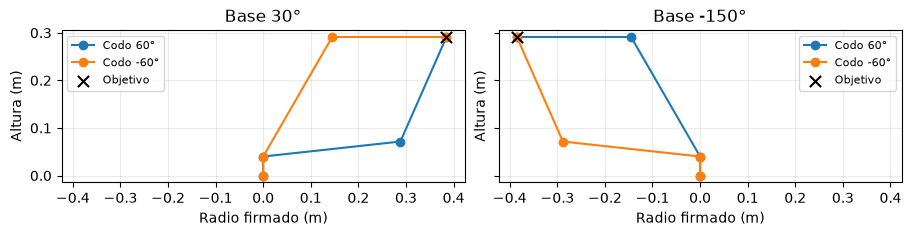

In [6]:
limit = 1.1 * max(radius, l2, l3)
fig, axes = plt.subplots(1, len(bases), figsize=(9, 4), sharey=True, squeeze=False, layout="constrained")
for ax, (direction, r) in zip(axes[0], bases):
    for q1, q2, q3 in solutions:
        if np.cos(q1 - direction) > 0.99:
            tip = position([q1, q2, q3])
            tip_r = tip[0]*np.cos(q1) + tip[1]*np.sin(q1)
            ax.plot([0, 0, l2*np.cos(q2), tip_r], [0, l1, l1 + l2*np.sin(q2), tip[2]],
                    "o-", label=f"Codo {np.rad2deg(q3):.0f}°")
    ax.scatter(r, z, color="black", marker="x", s=65, zorder=4, label="Objetivo")
    ax.set(title=f"Base {np.rad2deg((direction + np.pi) % (2*np.pi) - np.pi):.0f}°",
           xlabel="Radio firmado (m)", ylabel="Altura (m)", xlim=(-limit, limit))
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
plt.show()

**Para explorar:** sustituir el objetivo por `[0.53, 0, l1]` (extensión), `[0, 0, 0.30]` (base libre) o `[0.60, 0, l1]` (inalcanzable) y volver a ejecutar. La comparación se refiere a la posición del modelo nominal. La orientación, los límites articulares y las colisiones pueden restringir la elección física.